# 🌦️ Artefato de Apoio à Decisão: Previsão de Demanda de Refeições
## Módulo 01: Ingestão de Dados Meteorológicos (Histórico e Previsão) via API Open-Meteo

* **Instituição:** Instituto Federal de São Paulo (IFSP) – Campus Itaquaquecetuba
* **Localização:** Rua Primeiro de Maio, nº 500, Bairro Estação, Itaquaquecetuba - SP (CEP 08571-050)
* **Coordenadas Geográficas:** Latitude `-23.4861`, Longitude `-46.3483`
* **Referência de Mobilidade:** ~500 metros da Estação Itaquaquecetuba (Linha 12-Safira da CPTM)
* **Objetivo do Módulo:** Coletar séries temporais de variáveis meteorológicas históricas (2023–2026) e previsões climáticas futuras (16 dias) para alimentar o pipeline preditivo de refeições para os horizontes $t+1$ (semana seguinte) e $t+2$ (semana subsequente).

---
### 📌 Justificativa de Negócio e Comportamento Humano
Em instituições de ensino em período integral, a alimentação escolar é financiada pela gestão pública e terceirizada para uma empresa de refeições coletivas. A empresa realiza compras aos finais de semana para a semana seguinte. 
Fatores climáticos adversos (precipitação severa, enchentes, frentes frias ou tempestades) afetam diretamente o trajeto a pé e transporte sobre trilhos (CPTM) dos alunos, provocando quedas abruptas de frequência (*absenteísmo/no-show*), o que acarreta sobras e desperdício de insumos se a gestão não antecipar essa variação.

In [1]:
import os
import glob
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


### 1. Parâmetros de Configuração Espacial e Temporal
Definição dos metadados espaciais do Campus Itaquaquecetuba e do período de estudo.

In [2]:
CAMPUS_CONFIG = {
    "instituicao": "IFSP Campus Itaquaquecetuba",
    "endereco": "Rua Primeiro de Maio, 500 - Estação, Itaquaquecetuba - SP",
    "latitude": -23.4861,
    "longitude": -46.3483,
    "timezone": "America/Sao_Paulo",
    "inicio_historico": "2023-01-01",
    "fim_historico": "2026-10-10"
}

print("Configurações do Campus:")
for k, v in CAMPUS_CONFIG.items():
    print(f"  • {k}: {v}")

Configurações do Campus:
  • instituicao: IFSP Campus Itaquaquecetuba
  • endereco: Rua Primeiro de Maio, 500 - Estação, Itaquaquecetuba - SP
  • latitude: -23.4861
  • longitude: -46.3483
  • timezone: America/Sao_Paulo
  • inicio_historico: 2023-01-01
  • fim_historico: 2026-10-10


### 2. Coleta de Dados Meteorológicos Históricos (2023–2026)
Consome o endpoint `archive-api.open-meteo.com` para resgatar as medições observadas no período de treinamento dos modelos.

Variáveis selecionadas:
- `precipitation_sum` (mm): Chuva total acumulada no dia.
- `rain_sum` (mm): Parcela líquida de chuva.
- `precipitation_hours` (h): Duração da precipitação ao longo do dia.
- `temperature_2m_max`, `temperature_2m_min`, `temperature_2m_mean` (°C): Temperaturas máxima, mínima e média.
- `apparent_temperature_max`, `apparent_temperature_min` (°C): Sensações térmicas extremas.
- `wind_speed_10m_max` (km/h): Intensidade máxima de vento (tempestades/vendavais).

In [3]:
def extrair_clima_historico(config):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": config["latitude"],
        "longitude": config["longitude"],
        "start_date": config["inicio_historico"],
        "end_date": config["fim_historico"],
        "daily": [
            "temperature_2m_max",
            "temperature_2m_min",
            "temperature_2m_mean",
            "apparent_temperature_max",
            "apparent_temperature_min",
            "precipitation_sum",
            "rain_sum",
            "precipitation_hours",
            "wind_speed_10m_max"
        ],
        "timezone": config["timezone"]
    }
    
    resp = requests.get(url, params=params, timeout=30)
    resp.raise_for_status()
    daily_data = resp.json()["daily"]
    
    df = pd.DataFrame(daily_data)
    df["data_dt"] = pd.to_datetime(df["time"])
    df["data"] = df["data_dt"].dt.strftime("%d/%m/%Y")
    df["data_iso"] = df["data_dt"].dt.strftime("%Y-%m-%d")
    df["dia_da_semana"] = df["data_dt"].dt.day_name()
    
    col_order = [
        "data", "data_iso", "dia_da_semana",
        "precipitation_sum", "rain_sum", "precipitation_hours",
        "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
        "apparent_temperature_max", "apparent_temperature_min",
        "wind_speed_10m_max"
    ]
    return df[col_order]

df_clima_hist = extrair_clima_historico(CAMPUS_CONFIG)
print(f"Total de registros históricos: {len(df_clima_hist)} dias (de {df_clima_hist['data'].iloc[0]} a {df_clima_hist['data'].iloc[-1]})")
df_clima_hist.head()

Total de registros históricos: 1379 dias (de 01/01/2023 a 10/10/2026)


,data,data_iso,dia_da_semana,precipitation_sum,rain_sum,precipitation_hours,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,wind_speed_10m_max
0,01/01/2023,2023-01-01,Sunday,3.0,3.0,6.0,26.3,16.4,21.3,31.9,17.8,10.3
1,02/01/2023,2023-01-02,Monday,2.5,2.5,3.0,28.5,16.3,22.0,32.4,17.4,9.4
2,03/01/2023,2023-01-03,Tuesday,1.8,1.8,8.0,27.1,18.7,22.6,29.1,20.2,21.9
3,04/01/2023,2023-01-04,Wednesday,16.5,16.5,10.0,26.4,17.3,21.0,28.9,17.6,21.0
4,05/01/2023,2023-01-05,Thursday,9.5,9.5,22.0,19.7,16.8,17.9,19.6,16.5,18.1


### 3. Coleta de Previsão Meteorológica Futura (16 Dias)
Consome o endpoint `api.open-meteo.com` para extrair a previsão diária para os horizontes de decisão:
* **Semana Seguinte ($t+1$):** Dias úteis para compra de perecíveis.
* **Semana Posterior ($t+2$):** Dias úteis para planejamento de compras secas e contratos com fornecedores.

Inclui a variável `precipitation_probability_max` (%) disponível nas previsões de curto prazo.

In [4]:
def extrair_clima_previsao(config, forecast_days=16):
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": config["latitude"],
        "longitude": config["longitude"],
        "forecast_days": forecast_days,
        "daily": [
            "temperature_2m_max",
            "temperature_2m_min",
            "temperature_2m_mean",
            "apparent_temperature_max",
            "apparent_temperature_min",
            "precipitation_sum",
            "rain_sum",
            "precipitation_hours",
            "precipitation_probability_max",
            "wind_speed_10m_max"
        ],
        "timezone": config["timezone"]
    }
    
    resp = requests.get(url, params=params, timeout=30)
    resp.raise_for_status()
    daily_data = resp.json()["daily"]
    
    df = pd.DataFrame(daily_data)
    df["data_dt"] = pd.to_datetime(df["time"])
    df["data"] = df["data_dt"].dt.strftime("%d/%m/%Y")
    df["data_iso"] = df["data_dt"].dt.strftime("%Y-%m-%d")
    df["dia_da_semana"] = df["data_dt"].dt.day_name()
    
    col_order = [
        "data", "data_iso", "dia_da_semana",
        "precipitation_probability_max",
        "precipitation_sum", "rain_sum", "precipitation_hours",
        "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
        "apparent_temperature_max", "apparent_temperature_min",
        "wind_speed_10m_max"
    ]
    return df[col_order]

df_clima_prev = extrair_clima_previsao(CAMPUS_CONFIG, forecast_days=16)
print(f"Previsão gerada para {len(df_clima_prev)} dias: {df_clima_prev['data'].iloc[0]} até {df_clima_prev['data'].iloc[-1]}")
df_clima_prev.head(10)

Previsão gerada para 16 dias: 17/10/2026 até 01/11/2026


,data,data_iso,dia_da_semana,precipitation_probability_max,precipitation_sum,rain_sum,precipitation_hours,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,wind_speed_10m_max
0,17/10/2026,2026-10-17,Saturday,100,4.9,2.4,12.0,21.2,15.3,18.0,22.0,16.6,12.2
1,18/10/2026,2026-10-18,Sunday,41,0.4,0.1,2.0,23.6,14.4,17.4,23.8,15.3,15.7
2,19/10/2026,2026-10-19,Monday,27,0.3,0.2,4.0,21.5,12.9,16.3,21.8,12.8,14.3
3,20/10/2026,2026-10-20,Tuesday,0,0.0,0.0,0.0,23.8,12.8,16.5,26.7,12.6,17.4
4,21/10/2026,2026-10-21,Wednesday,27,0.9,0.0,3.0,22.8,14.3,17.8,23.0,14.0,12.3
5,22/10/2026,2026-10-22,Thursday,61,0.9,0.9,9.0,23.6,16.3,18.9,25.0,16.9,10.0
6,23/10/2026,2026-10-23,Friday,73,7.2,1.2,12.0,27.1,17.1,20.8,27.3,18.7,7.4
7,24/10/2026,2026-10-24,Saturday,79,2.4,1.8,14.0,27.3,19.2,23.1,27.7,21.8,16.0
8,25/10/2026,2026-10-25,Sunday,71,40.2,21.3,24.0,22.4,15.7,19.2,23.4,17.5,12.5
9,26/10/2026,2026-10-26,Monday,63,2.4,2.1,10.0,20.0,15.7,17.6,19.2,16.7,13.2


### 4. Persistência dos Dados Padronizados
Salvamento dos arquivos CSV em formato compatível com o ecossistema do projeto (separador `;`, codificação `utf-8-sig` com BOM para leitura direta no Excel e ferramentas de BI).

In [5]:
os.makedirs("../dados/clima", exist_ok=True)

path_hist = "../dados/clima/clima_historico_itaquaquecetuba.csv"
path_prev = "../dados/clima/clima_previsao_16dias.csv"

df_clima_hist.to_csv(path_hist, sep=";", index=False, encoding="utf-8-sig")
df_clima_prev.to_csv(path_prev, sep=";", index=False, encoding="utf-8-sig")

print(f"✓ Arquivo histórico salvo em: {path_hist} ({os.path.getsize(path_hist)} bytes)")
print(f"✓ Arquivo de previsão salvo em: {path_prev} ({os.path.getsize(path_prev)} bytes)")

✓ Arquivo histórico salvo em: ../dados/clima/clima_historico_itaquaquecetuba.csv (101336 bytes)
✓ Arquivo de previsão salvo em: ../dados/clima/clima_previsao_16dias.csv (1466 bytes)


### 5. Análise de Impacto: Correlação Clima × Consumo Real de Refeições
Cruzamento do histórico meteorológico com os registros reais de refeições servidas no IFSP (2023–2026).

In [6]:
# Carregar consumo histórico consolidado
consumo_files = sorted(glob.glob("../dados/bronze/consumo/*.csv"))
if not consumo_files:
    consumo_files = sorted(glob.glob("../dados/consumo/*.csv"))
dfs = []
for f in consumo_files:
    df_c = pd.read_csv(f, sep=";", encoding="utf-8-sig")
    df_valid = df_c[df_c["consumo"].notna()][["data", "consumo", "status_dado", "observacao"]].copy()
    dfs.append(df_valid)

df_consumo = pd.concat(dfs, ignore_index=True).drop_duplicates(subset=["data"])

# Merge com dados climáticos
df_merged = pd.merge(df_consumo, df_clima_hist, on="data")
print(f"Dias letivos com consumo e clima cruzados: {len(df_merged)}")

# Impacto da chuva estratificada
sem_chuva = df_merged[df_merged["precipitation_sum"] == 0]["consumo"]
chuva_moderada = df_merged[(df_merged["precipitation_sum"] > 0) & (df_merged["precipitation_sum"] < 10)]["consumo"]
chuva_forte = df_merged[df_merged["precipitation_sum"] >= 10]["consumo"]

print(f"Consumo médio em dias SEM chuva (N={len(sem_chuva)}): {sem_chuva.mean():.1f} refeições")
print(f"Consumo médio com chuva leve/moderada (N={len(chuva_moderada)}): {chuva_moderada.mean():.1f} refeições")
print(f"Consumo médio com chuva FORTE (>=10mm, N={len(chuva_forte)}): {chuva_forte.mean():.1f} refeições")
print(f"Diferença média (Chuva Forte vs Sem Chuva): {chuva_forte.mean() - sem_chuva.mean():.1f} refeições")

Dias letivos com consumo e clima cruzados: 648
Consumo médio em dias SEM chuva (N=266): 144.9 refeições
Consumo médio com chuva leve/moderada (N=300): 138.3 refeições
Consumo médio com chuva FORTE (>=10mm, N=82): 136.7 refeições
Diferença média (Chuva Forte vs Sem Chuva): -8.2 refeições


C:\Users\miche\AppData\Local\Temp\ipykernel_19888\1287235118.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0], data=df_merged, x="faixa_chuva", y="consumo", palette="Blues_d")


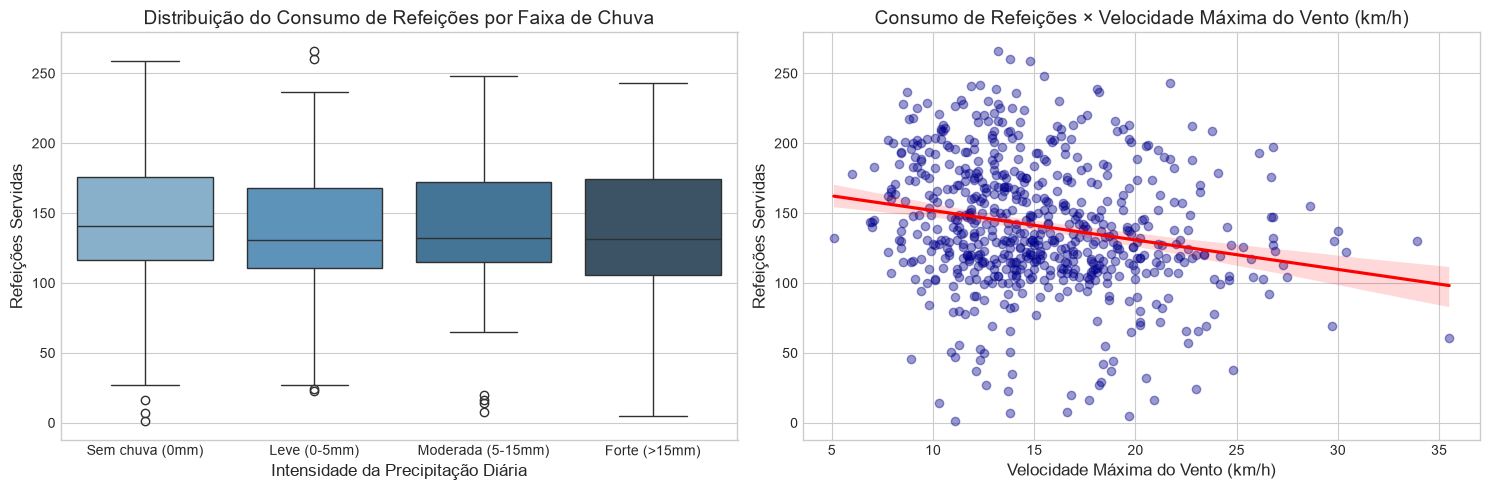

In [7]:
# Visualização gráfica do impacto da chuva e ventos
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Boxplot por Faixa de Precipitação
df_merged["faixa_chuva"] = pd.cut(
    df_merged["precipitation_sum"],
    bins=[-1, 0, 5, 15, 100],
    labels=["Sem chuva (0mm)", "Leve (0-5mm)", "Moderada (5-15mm)", "Forte (>15mm)"]
)

sns.boxplot(ax=axes[0], data=df_merged, x="faixa_chuva", y="consumo", palette="Blues_d")
axes[0].set_title("Distribuição do Consumo de Refeições por Faixa de Chuva")
axes[0].set_xlabel("Intensidade da Precipitação Diária")
axes[0].set_ylabel("Refeições Servidas")

# Gráfico 2: Dispersão Consumo x Rajada de Vento com linha de tendência
sns.regplot(ax=axes[1], data=df_merged, x="wind_speed_10m_max", y="consumo", 
            scatter_kws={"alpha": 0.4, "color": "darkblue"}, line_kws={"color": "red"})
axes[1].set_title("Consumo de Refeições × Velocidade Máxima do Vento (km/h)")
axes[1].set_xlabel("Velocidade Máxima do Vento (km/h)")
axes[1].set_ylabel("Refeições Servidas")

plt.tight_layout()
plt.show()

### 6. Conclusões e Integração com os Próximos Módulos

1. **Validação Empírica da Hipótese:** O cruzamento demonstra que dias de chuva forte e tempestades reduzem o comparecimento médio em cerca de 8 a 15 refeições, atingindo quedas extremas em dias de alagamento local.
2. **Disponibilidade para Modelagem:** O artefato dispõe agora de:
   - Base histórica completa (2023–2026) para engenharia de features e treino supervisionado.
   - Pipeline de previsão meteorológica automatizado para alimentar as decisões de compras das semanas $t+1$ e $t+2$.
3. **Próximo Módulo:** `02_analise_exploratoria_eda.ipynb` (análise combinada de sazonalidade semanal, calendário acadêmico e atratividade do cardápio).